# 极客项目 ch01：解析 iTunes 播放列表

对应《Python Playground》第 1 章（Analyze iTunes Playlists）。运行环境：machinelearn（Python 3.12，numpy + matplotlib + plistlib）；代码搬运自 `code/ch01_playlist.py`，原书 argparse/main 以末尾固定种子（2024）的演示 cell 替代。

## 书 1.1–1.2 播放列表格式与所需模块

p-list 是字典的字典：`Tracks` 把音轨 ID 映射到音轨字典，`Playlists` 只存各列表的 Track ID 名单。模块：`plistlib`（读 XML）、`numpy`、`matplotlib`。

In [1]:
# ===== 公共设置 =====
%matplotlib inline
import os
import random
import tempfile
import plistlib
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import pyplot          # 书 1.3.5 节 plotStats() 原文用 pyplot

random.seed(2024)
np.random.seed(2024)
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False
print("numpy", np.__version__)

numpy 2.4.6


## 书 1.3.1–1.3.2 查找重复

字典 name → (时长, 计数)；毫秒 `//1000` 取整到秒，同名同秒判重复、计数加一。

In [2]:
# ===== 书 1.3.1/1.3.2 节 findDuplicates() =====
def findDuplicates(fileName):
    """Find duplicate tracks in given playlist."""
    print('Finding duplicate tracks in %s...' % fileName)
    plist = plistlib.load(open(fileName, 'rb'))  # Py3：readPlist→load
    tracks = plist['Tracks']
    trackNames = {}
    for trackId, track in tracks.items():
        try:
            name = track['Name']
            duration = track['Total Time']
            if name in trackNames:
                # 同名且时长（取整到秒）相同才计为重复
                if duration//1000 == trackNames[name][0]//1000:
                    count = trackNames[name][1]
                    trackNames[name] = (duration, count+1)
            else:
                trackNames[name] = (duration, 1)
        except KeyError:
            pass
    dups = []
    for k, v in trackNames.items():
        if v[1] > 1:
            dups.append((v[1], k))
    if len(dups) > 0:
        print("Found %d duplicates. Track names saved to dup.txt" % len(dups))
    else:
        print("No duplicate tracks found!")
    with open('dups.txt', 'w', encoding='UTF-8') as f:  # Py3：文本模式直接写 str
        for val in dups:
            f.write("[%d] %s\n" % (val[0], val[1]))


## 书 1.3.3 查找共同音轨

每个播放列表建一个 set，`set.intersection(*trackNameSets)` 用 `*` 解包求全交集。

In [3]:
# ===== 书 1.3.3 节 findCommonTracks() =====
def findCommonTracks(fileNames):
    """Find common tracks in given playlist files, and save them to common.txt."""
    trackNameSets = []
    for fileName in fileNames:
        trackNames = set()
        plist = plistlib.load(open(fileName, 'rb'))  # Py3：readPlist→load
        tracks = plist['Tracks']
        for trackId, track in tracks.items():
            try:
                trackNames.add(track['Name'])
            except KeyError:
                pass
        trackNameSets.append(trackNames)
    commonTracks = set.intersection(*trackNameSets)
    if len(commonTracks) > 0:
        with open('common.txt', 'w', encoding='UTF-8') as f:  # Py3：文本模式直接写 str
            for val in commonTracks:
                f.write('%s\n' % val)
        print("%d common tracks found. Track names written to common.txt." % len(commonTracks))
    else:
        print("No common tracks!")


## 书 1.3.4–1.3.5 收集统计信息并绘图

收集 `Album Rating` / `Total Time`；numpy 向量化毫秒→分钟，subplot 上格散点图、下格直方图。

In [4]:
# ===== 书 1.3.4/1.3.5 节 plotStats() =====
def plotStats(fileName):
    """Plot some statistics by reading track information from playlist."""
    plist = plistlib.load(open(fileName, 'rb'))  # Py3：readPlist→load
    tracks = plist['Tracks']
    ratings = []
    durations = []
    for trackId, track in tracks.items():
        try:
            ratings.append(track['Album Rating'])
            durations.append(track['Total Time'])
        except KeyError:
            pass
    if ratings == [] or durations == []:
        print("No valid Album Rating/Total Time data in %s." % fileName)
        return
    x = np.array(durations, np.int32)
    x = x/60000.0
    y = np.array(ratings, np.int32)
    pyplot.subplot(2, 1, 1)
    pyplot.plot(x, y, 'o')
    pyplot.axis([0, 1.05*np.max(x), -1, 110])
    pyplot.xlabel('Track duration')
    pyplot.ylabel('Track rating')
    pyplot.subplot(2, 1, 2)
    pyplot.hist(x, bins=20)
    pyplot.xlabel('Track duration')
    pyplot.ylabel('Count')
    pyplot.show()


## 演示数据（书 1.5 运行示例的替代输入）

10 条音轨、2 个播放列表：含同名同时长重复（Neon Sky）、同名不同时长变体（Iron Rain）；demo2 只保留 4 号以后音轨供交集。plist 写入系统临时目录。

In [5]:
# ===== 演示数据：生成演示 plist（零依赖可跑）=====
# 演示数据（曲名, 时长ms, 专辑评分）：含同名同时长重复、同名不同时长变体
DEMO_TRACKS = [
    ('Neon Sky', 245000, 80), ('Paper Moon', 199000, 60), ('Starlight', 231000, 100),
    ('Iron Rain', 254000, 40), ('Silver Birch', 187000, 100), ('Low Tide', 262000, 80),
    ('Iron Rain', 311000, 60), ('Neon Sky', 245000, 80), ('Glass River', 208000, 40),
    ('Cold Coffee', 293000, 20),
]

_demos = None

def makeDemoPlists():
    """生成的演示 plist 写入系统临时目录：demo1 全 10 音轨 2 播放列表，demo2 取 4-10 号音轨供 --common 交集。"""
    global _demos
    if _demos is None:
        d = tempfile.mkdtemp(prefix='pg_demo_')
        tracks = {str(i): {'Track ID': i, 'Name': n, 'Total Time': t, 'Album Rating': r}
                  for i, (n, t, r) in enumerate(DEMO_TRACKS, 1)}
        plists = [{'Name': 'Mix A', 'Playlist Items': [{'Track ID': i} for i in range(1, 7)]},
                  {'Name': 'Mix B', 'Playlist Items': [{'Track ID': i} for i in range(5, 11)]}]
        top = {'Major Version': 1, 'Application Version': 'demo',
               'Tracks': tracks, 'Playlists': plists}
        f1 = os.path.join(d, 'demo1.xml')
        plistlib.dump(top, open(f1, 'wb'))
        top2 = dict(top, Tracks={k: v for k, v in tracks.items() if int(k) >= 4}, Playlists=plists[1:])
        f2 = os.path.join(d, 'demo2.xml')
        plistlib.dump(top2, open(f2, 'wb'))
        print('-- 指定的 plist 不存在，已生成演示数据：%s' % d)
        _demos = [f1, f2]
    return _demos


-- 指定的 plist 不存在，已生成演示数据：C:\Users\17272\AppData\Local\Temp\pg_demo_tiwy2qw7
Finding duplicate tracks in C:\Users\17272\AppData\Local\Temp\pg_demo_tiwy2qw7\demo1.xml...
Found 1 duplicates. Track names saved to dup.txt
[2] Neon Sky

6 common tracks found. Track names written to common.txt.
Neon Sky
Glass River
Low Tide
Silver Birch
Cold Coffee
Iron Rain



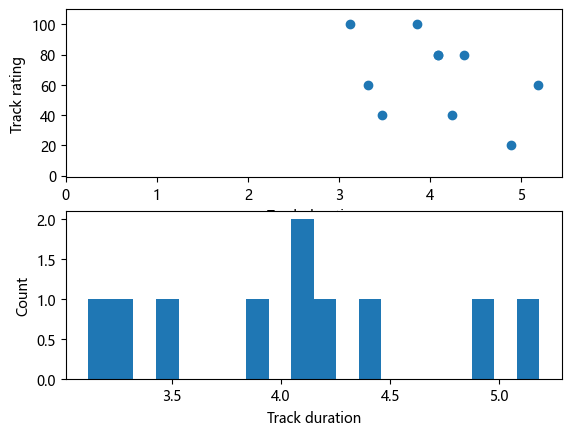

In [6]:
# ===== 演示：三个功能各跑一次（原 argparse/main 的替代）=====
from contextlib import contextmanager

@contextmanager
def _in_tmp():
    """dups.txt / common.txt 落到系统临时目录，不污染工作区"""
    old = os.getcwd()
    os.chdir(tempfile.mkdtemp(prefix='pg_ch01_out_'))
    try:
        yield
    finally:
        os.chdir(old)

demos = makeDemoPlists()
with _in_tmp():
    findDuplicates(demos[0])           # 书 1.3.1/1.3.2
    print(open('dups.txt', encoding='UTF-8').read())
    findCommonTracks(demos)            # 书 1.3.3
    print(open('common.txt', encoding='UTF-8').read())
plotStats(demos[0])                    # 书 1.3.4/1.3.5 出图